# Future Failure prediction using the Random Forest model

In [1]:
import numpy as np
import pandas as pd

In [2]:
atm = pd.read_csv(r'Dataset/ATM_Maintenance_Cleaned.csv', parse_dates=['Date'])
atm

,Date,ATM_ID,District,Location_Type,Manufacturer,ATM_Age_Yrs,Daily_Transactions,Failed_Transactions,Cash_Remaining_Pct,Cash_Loaded_Today,...,Memory_Usage_Pct,Network_Latency_ms,Network_Drops,UPS_Battery_Pct,Power_Outages_7D,Days_Since_Maintenance,Previous_Failures_90D,Customer_Complaints_7D,Failure_Code,Failure_Next_48H
0,2025-01-01,ATM058,Idukki,Hospital,NCR,1.2,429,15,69.0,0,...,52,46,0,78,2,29,4,1,5,1
1,2025-01-02,ATM173,Kozhikode,Railway,Diebold,1.9,343,6,43.0,0,...,45,10,0,92,3,58,1,0,2,1
2,2025-01-03,ATM187,Malappuram,Airport,Diebold,2.5,285,10,78.0,0,...,53,66,2,88,0,63,0,0,0,0
3,2025-01-04,ATM256,Alappuzha,Rural,Diebold,4.6,488,22,39.0,0,...,67,95,1,68,1,54,0,0,5,1
4,2025-01-05,ATM284,Thrissur,Hospital,NCR,8.7,736,25,57.0,0,...,54,56,3,97,4,57,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,2025-12-22,ATM153,Kottayam,Airport,Diebold,8.1,595,29,69.0,0,...,58,177,0,79,3,5,0,0,1,1
49996,2025-12-23,ATM229,Kollam,Airport,Hitachi,7.3,578,11,85.0,1,...,67,41,3,77,3,70,6,1,0,0
49997,2025-12-24,ATM247,Thrissur,Hospital,Diebold,6.2,656,1,35.0,0,...,65,64,0,89,0,43,4,2,0,0
49998,2025-12-25,ATM184,Kottayam,Railway,NCR,1.9,471,19,62.0,0,...,71,114,0,100,1,0,2,3,1,1


In [3]:
atm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 27 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Date                    50000 non-null  datetime64[ns]
 1   ATM_ID                  50000 non-null  object        
 2   District                50000 non-null  object        
 3   Location_Type           50000 non-null  object        
 4   Manufacturer            50000 non-null  object        
 5   ATM_Age_Yrs             50000 non-null  float64       
 6   Daily_Transactions      50000 non-null  int64         
 7   Failed_Transactions     50000 non-null  int64         
 8   Cash_Remaining_Pct      50000 non-null  float64       
 9   Cash_Loaded_Today       50000 non-null  int64         
 10  CardReader_Errors       50000 non-null  int64         
 11  CashDispenser_Errors    50000 non-null  int64         
 12  Cash_Jams               50000 non-null  int64 

In [4]:
atm["ATM_ID"].unique()

array(['ATM058', 'ATM173', 'ATM187', 'ATM256', 'ATM284', 'ATM272',
       'ATM109', 'ATM068', 'ATM230', 'ATM285', 'ATM021', 'ATM081',
       'ATM142', 'ATM053', 'ATM236', 'ATM161', 'ATM210', 'ATM172',
       'ATM266', 'ATM277', 'ATM215', 'ATM195', 'ATM059', 'ATM178',
       'ATM166', 'ATM252', 'ATM027', 'ATM157', 'ATM102', 'ATM129',
       'ATM206', 'ATM123', 'ATM260', 'ATM078', 'ATM250', 'ATM093',
       'ATM248', 'ATM071', 'ATM240', 'ATM114', 'ATM209', 'ATM125',
       'ATM136', 'ATM228', 'ATM160', 'ATM174', 'ATM218', 'ATM067',
       'ATM055', 'ATM039', 'ATM047', 'ATM199', 'ATM159', 'ATM237',
       'ATM213', 'ATM077', 'ATM044', 'ATM090', 'ATM189', 'ATM086',
       'ATM079', 'ATM029', 'ATM015', 'ATM074', 'ATM264', 'ATM193',
       'ATM294', 'ATM052', 'ATM019', 'ATM121', 'ATM042', 'ATM158',
       'ATM009', 'ATM154', 'ATM030', 'ATM171', 'ATM024', 'ATM251',
       'ATM007', 'ATM048', 'ATM092', 'ATM204', 'ATM003', 'ATM087',
       'ATM070', 'ATM036', 'ATM056', 'ATM287', 'ATM295', 'ATM0

In [5]:
atm["ATM_ID"].value_counts()

ATM_ID
ATM143    207
ATM013    204
ATM187    202
ATM193    200
ATM132    199
         ... 
ATM124    136
ATM103    135
ATM249    134
ATM108    133
ATM261    131
Name: count, Length: 300, dtype: int64

In [6]:
from sklearn.preprocessing import LabelEncoder

In [7]:
encoders = {}

for col in ['District', 'Location_Type', 'Manufacturer']:
    le = LabelEncoder()
    atm[col] = le.fit_transform(atm[col].astype(str))
    encoders[col] = le

In [8]:
atm

,Date,ATM_ID,District,Location_Type,Manufacturer,ATM_Age_Yrs,Daily_Transactions,Failed_Transactions,Cash_Remaining_Pct,Cash_Loaded_Today,...,Memory_Usage_Pct,Network_Latency_ms,Network_Drops,UPS_Battery_Pct,Power_Outages_7D,Days_Since_Maintenance,Previous_Failures_90D,Customer_Complaints_7D,Failure_Code,Failure_Next_48H
0,2025-01-01,ATM058,2,2,2,1.2,429,15,69.0,0,...,52,46,0,78,2,29,4,1,5,1
1,2025-01-02,ATM173,6,4,0,1.9,343,6,43.0,0,...,45,10,0,92,3,58,1,0,2,1
2,2025-01-03,ATM187,7,0,0,2.5,285,10,78.0,0,...,53,66,2,88,0,63,0,0,0,0
3,2025-01-04,ATM256,0,5,0,4.6,488,22,39.0,0,...,67,95,1,68,1,54,0,0,5,1
4,2025-01-05,ATM284,9,2,2,8.7,736,25,57.0,0,...,54,56,3,97,4,57,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,2025-12-22,ATM153,5,0,0,8.1,595,29,69.0,0,...,58,177,0,79,3,5,0,0,1,1
49996,2025-12-23,ATM229,4,0,1,7.3,578,11,85.0,1,...,67,41,3,77,3,70,6,1,0,0
49997,2025-12-24,ATM247,9,2,0,6.2,656,1,35.0,0,...,65,64,0,89,0,43,4,2,0,0
49998,2025-12-25,ATM184,5,4,2,1.9,471,19,62.0,0,...,71,114,0,100,1,0,2,3,1,1


In [9]:
# Sort data chronologically
atm = atm.sort_values('Date').reset_index(drop=True)
atm

,Date,ATM_ID,District,Location_Type,Manufacturer,ATM_Age_Yrs,Daily_Transactions,Failed_Transactions,Cash_Remaining_Pct,Cash_Loaded_Today,...,Memory_Usage_Pct,Network_Latency_ms,Network_Drops,UPS_Battery_Pct,Power_Outages_7D,Days_Since_Maintenance,Previous_Failures_90D,Customer_Complaints_7D,Failure_Code,Failure_Next_48H
0,2025-01-01,ATM058,2,2,2,1.2,429,15,69.0,0,...,52,46,0,78,2,29,4,1,5,1
1,2025-01-01,ATM171,4,1,0,4.7,713,19,21.0,0,...,51,14,0,100,2,102,0,0,1,1
2,2025-01-01,ATM198,9,0,1,4.7,461,16,38.0,0,...,56,58,3,97,3,40,0,3,0,0
3,2025-01-01,ATM186,3,5,1,6.0,657,15,70.0,0,...,80,114,0,74,0,64,2,0,0,0
4,2025-01-01,ATM186,3,5,2,1.8,238,5,50.0,1,...,64,103,0,87,0,54,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,2025-12-31,ATM150,0,4,2,5.9,497,7,35.0,0,...,62,59,2,89,0,7,0,2,0,0
49996,2025-12-31,ATM117,3,3,2,9.1,273,5,78.0,1,...,61,89,0,92,1,86,1,0,1,1
49997,2025-12-31,ATM297,7,1,1,5.7,212,2,28.0,0,...,75,10,0,88,0,97,2,2,5,1
49998,2025-12-31,ATM293,1,3,0,5.8,692,2,53.0,0,...,49,76,0,90,0,59,0,2,1,1


In [10]:
X = atm.drop(
    columns=[
        'Date',
        'ATM_ID',
        'Failure_Next_48H',
        'Failure_Code'])

y = atm['Failure_Next_48H']

In [11]:
X

,District,Location_Type,Manufacturer,ATM_Age_Yrs,Daily_Transactions,Failed_Transactions,Cash_Remaining_Pct,Cash_Loaded_Today,CardReader_Errors,CashDispenser_Errors,...,CPU_Temp_C,CPU_Usage_Pct,Memory_Usage_Pct,Network_Latency_ms,Network_Drops,UPS_Battery_Pct,Power_Outages_7D,Days_Since_Maintenance,Previous_Failures_90D,Customer_Complaints_7D
0,2,2,2,1.2,429,15,69.0,0,2,3,...,48.0,29,52,46,0,78,2,29,4,1
1,4,1,0,4.7,713,19,21.0,0,1,3,...,44.2,82,51,14,0,100,2,102,0,0
2,9,0,1,4.7,461,16,38.0,0,2,0,...,43.3,54,56,58,3,97,3,40,0,3
3,3,5,1,6.0,657,15,70.0,0,0,1,...,51.5,55,80,114,0,74,0,64,2,0
4,3,5,2,1.8,238,5,50.0,1,1,2,...,40.6,44,64,103,0,87,0,54,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,0,4,2,5.9,497,7,35.0,0,1,0,...,54.9,61,62,59,2,89,0,7,0,2
49996,3,3,2,9.1,273,5,78.0,1,1,3,...,51.3,69,61,89,0,92,1,86,1,0
49997,7,1,1,5.7,212,2,28.0,0,1,0,...,47.1,47,75,10,0,88,0,97,2,2
49998,1,3,0,5.8,692,2,53.0,0,0,3,...,36.2,68,49,76,0,90,0,59,0,2


In [12]:
y

0        1
1        1
2        0
3        0
4        0
        ..
49995    0
49996    1
49997    1
49998    1
49999    0
Name: Failure_Next_48H, Length: 50000, dtype: int64

In [13]:
# Time-based train-test split
split_index = int(len(atm) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:")
print(atm['Date'].iloc[0], "to", atm['Date'].iloc[split_index - 1])

print("\nTesting period:")
print(atm['Date'].iloc[split_index], "to", atm['Date'].iloc[-1])

Training records: 40000
Testing records: 10000

Training period:
2025-01-01 00:00:00 to 2025-10-19 00:00:00

Testing period:
2025-10-19 00:00:00 to 2025-12-31 00:00:00


### What does split_index mean?
- Suppose your dataset has 50,000 records (len(dataset)=50,000).
- By using "split_index = int(50000 * 0.80) = 400000" means;
   - First 40,000 records → Training
   - Last 10,000 records  → Testing
- Since the dataset is already sorted by dates;
   - Older data  -->  80% Training  -->  Model learns from past conditions 
   - Newer data  -->  20% Testing  -->  Model learns from future/later records

### Why using this spliting method?
- The aim of the project is to predict future ATM failures. Therefore, the records should be arranged in chronological order before splitting the data.
- By sorting the dataset according to the date, the model learns from earlier ATM conditions and is tested on later conditions.
- The dataset was sorted according to date to preserve the chronological order of ATM operations. Since the objective is to predict future failures, the model should learn from past observations and make predictions on later observations.

In [14]:
X_train

,District,Location_Type,Manufacturer,ATM_Age_Yrs,Daily_Transactions,Failed_Transactions,Cash_Remaining_Pct,Cash_Loaded_Today,CardReader_Errors,CashDispenser_Errors,...,CPU_Temp_C,CPU_Usage_Pct,Memory_Usage_Pct,Network_Latency_ms,Network_Drops,UPS_Battery_Pct,Power_Outages_7D,Days_Since_Maintenance,Previous_Failures_90D,Customer_Complaints_7D
0,2,2,2,1.2,429,15,69.0,0,2,3,...,48.0,29,52,46,0,78,2,29,4,1
1,4,1,0,4.7,713,19,21.0,0,1,3,...,44.2,82,51,14,0,100,2,102,0,0
2,9,0,1,4.7,461,16,38.0,0,2,0,...,43.3,54,56,58,3,97,3,40,0,3
3,3,5,1,6.0,657,15,70.0,0,0,1,...,51.5,55,80,114,0,74,0,64,2,0
4,3,5,2,1.8,238,5,50.0,1,1,2,...,40.6,44,64,103,0,87,0,54,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39995,3,4,1,9.4,505,13,68.0,1,1,0,...,43.0,56,63,19,4,100,0,31,0,0
39996,2,0,1,6.0,553,9,52.0,0,2,2,...,52.1,36,51,10,0,90,1,67,0,2
39997,9,3,0,5.0,908,40,58.0,0,0,1,...,40.8,60,65,112,0,84,3,38,0,0
39998,8,0,2,7.8,267,12,64.0,1,0,3,...,44.4,54,65,96,5,91,0,60,0,4


In [15]:
X_test

,District,Location_Type,Manufacturer,ATM_Age_Yrs,Daily_Transactions,Failed_Transactions,Cash_Remaining_Pct,Cash_Loaded_Today,CardReader_Errors,CashDispenser_Errors,...,CPU_Temp_C,CPU_Usage_Pct,Memory_Usage_Pct,Network_Latency_ms,Network_Drops,UPS_Battery_Pct,Power_Outages_7D,Days_Since_Maintenance,Previous_Failures_90D,Customer_Complaints_7D
40000,7,1,1,6.7,415,1,36.0,0,0,3,...,46.3,46,72,77,5,76,3,124,1,0
40001,1,1,0,2.2,369,5,77.0,0,2,1,...,52.3,50,73,110,1,88,2,84,0,2
40002,5,5,0,9.4,791,36,42.0,0,2,3,...,52.0,55,49,65,1,89,0,13,0,0
40003,6,5,2,4.5,606,4,38.0,0,2,0,...,42.7,52,76,136,3,92,0,31,0,0
40004,6,5,1,8.5,669,29,40.0,0,0,2,...,49.7,64,51,68,4,91,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,0,4,2,5.9,497,7,35.0,0,1,0,...,54.9,61,62,59,2,89,0,7,0,2
49996,3,3,2,9.1,273,5,78.0,1,1,3,...,51.3,69,61,89,0,92,1,86,1,0
49997,7,1,1,5.7,212,2,28.0,0,1,0,...,47.1,47,75,10,0,88,0,97,2,2
49998,1,3,0,5.8,692,2,53.0,0,0,3,...,36.2,68,49,76,0,90,0,59,0,2


In [16]:
y_train

0        1
1        1
2        0
3        0
4        0
        ..
39995    1
39996    0
39997    0
39998    1
39999    1
Name: Failure_Next_48H, Length: 40000, dtype: int64

In [17]:
y_test

40000    1
40001    0
40002    1
40003    0
40004    0
        ..
49995    0
49996    1
49997    1
49998    1
49999    0
Name: Failure_Next_48H, Length: 10000, dtype: int64

In [18]:
from sklearn.ensemble import RandomForestClassifier

In [19]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced')

### Why added class_weight='balanced'?
- If one class occurs less frequently than another, give more importance to the minority class.
- For example : No failure = 90% and Failure = 10%
- A model could simply predict "No failure" most of the time and still get high accuracy.
- Balanced class weights help prevent that behaviour

In [20]:
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [21]:
y_pred = model.predict(X_test)
y_pred

array([1, 0, 1, ..., 1, 1, 0], shape=(10000,))

In [22]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score)

In [23]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [24]:
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['No Failure', 'Failure']))


Classification Report:
               precision    recall  f1-score   support

  No Failure       1.00      1.00      1.00      5563
     Failure       1.00      1.00      1.00      4437

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000



### Model Evaluation
- The Random Forest model was evaluated using a time-based train-test split, where earlier records were used for training and later records were used for testing.
- Accuracy measures the overall proportion of correctly classified ATM records.
- Precision indicates how many ATMs predicted to fail actually failed.
- Recall is particularly important for ATM maintenance because it measures how many of the actual failure cases were successfully detected.
- F1-score provides a balance between precision and recall.
- The model performance should be interpreted based on the results obtained from the unseen, later-period test data.

In [25]:
importances = model.feature_importances_
feature_names = X.columns

In [26]:
importances

array([0.00208089, 0.00162185, 0.00093847, 0.00374719, 0.00433098,
       0.00302864, 0.00381117, 0.00048519, 0.00088423, 0.47057199,
       0.00050736, 0.47465483, 0.00354422, 0.00428532, 0.00358226,
       0.00361091, 0.00597315, 0.00142901, 0.00322918, 0.00130679,
       0.00359596, 0.00141229, 0.00136814])

In [27]:
feature_names

Index(['District', 'Location_Type', 'Manufacturer', 'ATM_Age_Yrs',
       'Daily_Transactions', 'Failed_Transactions', 'Cash_Remaining_Pct',
       'Cash_Loaded_Today', 'CardReader_Errors', 'CashDispenser_Errors',
       'Cash_Jams', 'Printer_Errors', 'Paper_Remaining_Pct', 'CPU_Temp_C',
       'CPU_Usage_Pct', 'Memory_Usage_Pct', 'Network_Latency_ms',
       'Network_Drops', 'UPS_Battery_Pct', 'Power_Outages_7D',
       'Days_Since_Maintenance', 'Previous_Failures_90D',
       'Customer_Complaints_7D'],
      dtype='object')

In [28]:
import matplotlib.pyplot as plt

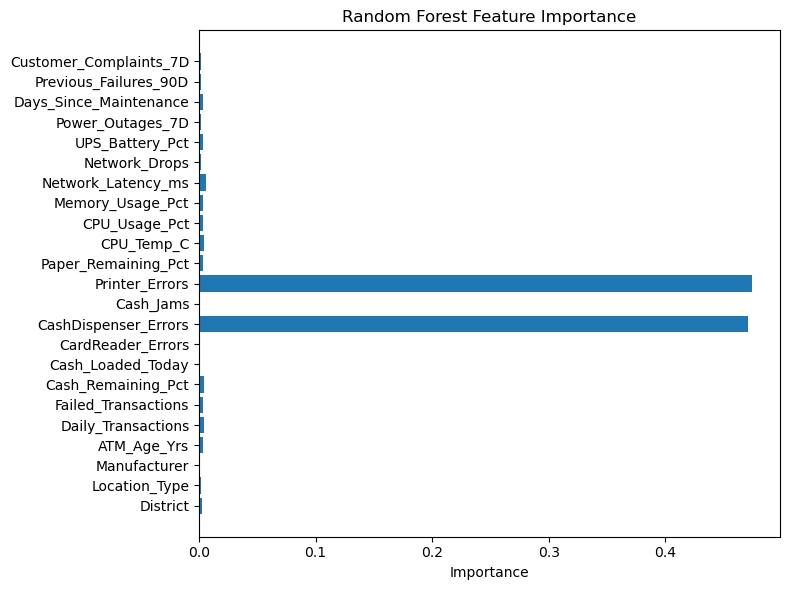

In [29]:
plt.figure(figsize=(8, 6))

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")

plt.barh(feature_names, importances)

plt.tight_layout()
plt.show()

- This graphs shows that , Printer_Errors and CashDispenser_Errors are the most important features for failure prediction.
- All other features have less importance.

In [30]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import classification_report, f1_score

# Create a small decision tree
dt_small = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Train
dt_small.fit(X_train, y_train)

# Predict
y_pred_dt = dt_small.predict(X_test)

# Evaluation
print("F1 Score:", f1_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=['No Failure', 'Failure']
))

# Print the rules learned by the tree
tree_rules = export_text(
    dt_small,
    feature_names=list(X_train.columns)
)

print("\nDecision Tree Rules:")
print(tree_rules)

F1 Score: 1.0

Classification Report:
              precision    recall  f1-score   support

  No Failure       1.00      1.00      1.00      5563
     Failure       1.00      1.00      1.00      4437

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000


Decision Tree Rules:
|--- Printer_Errors <= 2.50
|   |--- CashDispenser_Errors <= 2.50
|   |   |--- Network_Latency_ms <= 180.50
|   |   |   |--- class: 0
|   |   |--- Network_Latency_ms >  180.50
|   |   |   |--- class: 1
|   |--- CashDispenser_Errors >  2.50
|   |   |--- class: 1
|--- Printer_Errors >  2.50
|   |--- class: 1



In [31]:
# Recreate the apparent failure rule
rule = (
    (atm['Printer_Errors'] >= 3) |
    (atm['CashDispenser_Errors'] >= 3) |
    (atm['Network_Latency_ms'] > 180)
).astype(int)

# Compare the rule with the actual target
rule_accuracy = (rule == atm['Failure_Next_48H']).mean()

print("Rule match:", rule_accuracy)

Rule match: 1.0


In [32]:
mismatches = atm[rule != atm['Failure_Next_48H']]

print("Number of mismatches:", len(mismatches))

Number of mismatches: 0


## Creating a Simulated Noisy Target

### Why a Simulated Noisy Target is Introduced

The initial Random Forest model achieved perfect performance with an accuracy and F1-score of 1.00. Since perfect prediction is unusual in real-world failure prediction problems, the result was investigated further.

Feature importance analysis showed that `Printer_Errors` and `CashDispenser_Errors` dominated the predictions. A shallow Decision Tree was then used to examine the relationship between the features and the target. It revealed that `Failure_Next_48H` could be perfectly determined using a simple rule involving:

- `Printer_Errors`
- `CashDispenser_Errors`
- `Network_Latency_ms`

The rule was verified against the complete dataset and matched the original target perfectly. This indicates that the synthetic target was generated using a deterministic rule rather than containing the uncertainty normally present in real-world equipment failures.

Therefore, a separate target called `Failure_Noisy` is created for a simulated experiment. Controlled label changes are introduced so that the warning conditions do not always result in failure and failures can occasionally occur outside the original rule.

The original `Failure_Next_48H` column is kept unchanged.

**Important:** The added noise is simulated and does not represent observed real-world ATM failure behaviour. This experiment is used only to demonstrate model development and evaluation under a less deterministic scenario.

In [33]:
# Create a copy of the original target
atm['Failure_Noisy'] = atm['Failure_Next_48H'].copy()

# Check both columns
atm[['Failure_Next_48H', 'Failure_Noisy']].head(10)

,Failure_Next_48H,Failure_Noisy
0,1,1
1,1,1
2,0,0
3,0,0
4,0,0
5,1,1
6,0,0
7,0,0
8,0,0
9,1,1


In [34]:
print(
    "Different values:",
    (atm['Failure_Next_48H'] != atm['Failure_Noisy']).sum()
)

Different values: 0


In [35]:
# Get indices of failure and no-failure records
failure_indices = atm.index[
    atm['Failure_Next_48H'] == 1
]

no_failure_indices = atm.index[
    atm['Failure_Next_48H'] == 0
]

print("Failure records:", len(failure_indices))
print("No Failure records:", len(no_failure_indices))

Failure records: 21767
No Failure records: 28233


In [36]:
# Set random seed for reproducibility
np.random.seed(42)

# Randomly select 10% of failure records
failure_to_flip = np.random.choice(
    failure_indices,
    size=int(len(failure_indices) * 0.10),
    replace=False
)

# Randomly select 5% of no-failure records
no_failure_to_flip = np.random.choice(
    no_failure_indices,
    size=int(len(no_failure_indices) * 0.05),
    replace=False
)

print("Failures selected to change:", len(failure_to_flip))
print("No Failures selected to change:", len(no_failure_to_flip))

Failures selected to change: 2176
No Failures selected to change: 1411


In [37]:
# Change selected Failure records from 1 to 0
atm.loc[failure_to_flip, 'Failure_Noisy'] = 0

# Change selected No Failure records from 0 to 1
atm.loc[no_failure_to_flip, 'Failure_Noisy'] = 1

In [38]:
# Count how many labels are different
changed = (
    atm['Failure_Next_48H'] != atm['Failure_Noisy']
).sum()

print("Number of labels changed:", changed)
print(
    "Percentage of total records changed:",
    round(changed / len(atm) * 100, 2),
    "%"
)

print("\nOriginal target:")
print(atm['Failure_Next_48H'].value_counts())

print("\nNoisy target:")
print(atm['Failure_Noisy'].value_counts())

Number of labels changed: 3587
Percentage of total records changed: 7.17 %

Original target:
Failure_Next_48H
0    28233
1    21767
Name: count, dtype: int64

Noisy target:
Failure_Noisy
0    28998
1    21002
Name: count, dtype: int64


In [39]:
# Create noisy target
y_noisy = atm['Failure_Noisy']

# Use the SAME time-based split
y_train_noisy = y_noisy.iloc[:split_index]
y_test_noisy = y_noisy.iloc[split_index:]

print("Training records:", len(y_train_noisy))
print("Testing records:", len(y_test_noisy))

print("\nTraining target:")
print(y_train_noisy.value_counts())

print("\nTesting target:")
print(y_test_noisy.value_counts())

Training records: 40000
Testing records: 10000

Training target:
Failure_Noisy
0    23257
1    16743
Name: count, dtype: int64

Testing target:
Failure_Noisy
0    5741
1    4259
Name: count, dtype: int64


In [40]:
final_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)

final_model.fit(X_train, y_train_noisy)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [41]:
y_pred_noisy = final_model.predict(X_test)

In [42]:
print("Accuracy:",
      round(accuracy_score(y_test_noisy, y_pred_noisy), 3))

print("\nClassification Report:")
print(
    classification_report(
        y_test_noisy,
        y_pred_noisy,
        target_names=['No Failure', 'Failure']
    )
)

Accuracy: 0.93

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.95      0.92      0.94      5741
     Failure       0.90      0.94      0.92      4259

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



In [43]:
from sklearn.metrics import ConfusionMatrixDisplay

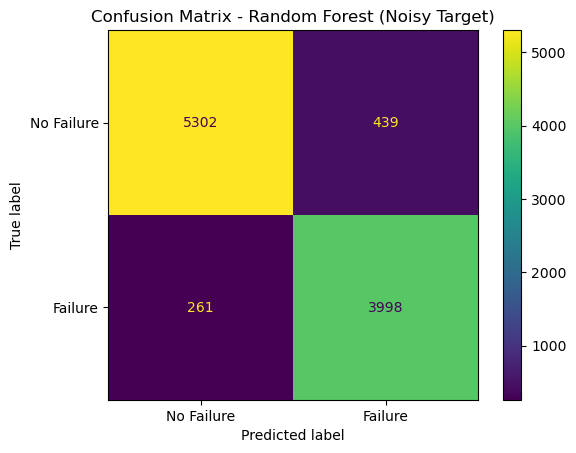

In [44]:
cm = confusion_matrix(y_test_noisy, y_pred_noisy)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Failure', 'Failure']
)

disp.plot()
plt.title('Confusion Matrix - Random Forest (Noisy Target)')
plt.show()

In [45]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

True Negatives : 5302
False Positives: 439
False Negatives: 261
True Positives : 3998


### Confusion Matrix Interpretation

The Random Forest correctly identified 3,998 failure cases and 5,302 no-failure cases.

It produced 439 false positives, where an ATM was predicted to fail but did not, and 261 false negatives, where an actual failure was missed.

The model achieved a recall of approximately 94% for the Failure class, indicating that it detected most failure cases in the simulated noisy-target experiment. In a preventive maintenance scenario, recall is particularly important because false negatives represent failures that would not receive an early maintenance warning.

These results are based on a synthetically modified target and should not be interpreted as expected performance on real-world ATM failure data.

## Time-Series Cross-Validation
### Why Time-Series Cross-Validation is Used

After introducing the simulated noisy target, the Random Forest achieved approximately 93% accuracy and a Failure recall of approximately 94% on the chronological test set.

However, this result is based on a single 80/20 train-test split. A model may perform well on one test period but perform differently during other periods.

Since the ATM records contain a time component, ordinary random cross-validation is not appropriate. Random splitting could allow later observations to be used for training while earlier observations are used for validation, which would not represent the real prediction scenario.

Therefore, `TimeSeriesSplit` is used.

Time-series cross-validation evaluates the model across multiple chronological training and validation periods. In each split, the model is trained using earlier records and evaluated on later records.

This helps determine whether the model's performance is reasonably consistent across different time periods rather than being dependent on one particular train-test split.

The F1-score for the Failure class is used as the cross-validation metric because it provides a balance between detecting actual failures (recall) and limiting false failure alerts (precision).

In [46]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

In [47]:
# Prepare features for cross-validation
X_all = atm.drop(columns=[
    'Date',
    'ATM_ID',
    'Failure_Code',
    'Failure_Next_48H',
    'Failure_Noisy'
])

# Simulated noisy target
y_all = atm['Failure_Noisy']

print("Feature shape:", X_all.shape)
print("Target shape:", y_all.shape)

Feature shape: (50000, 23)
Target shape: (50000,)


In [48]:
# Create 5 chronological splits
tscv = TimeSeriesSplit(n_splits=5)

print("Number of splits:", tscv.get_n_splits())

Number of splits: 5


In [49]:
cv_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)

In [50]:
f1_scores = cross_val_score(
    cv_model,
    X_all,
    y_all,
    cv=tscv,
    scoring='f1'
)

In [51]:
print("F1 Scores for Each Fold:")

for i, score in enumerate(f1_scores, start=1):
    print(f"Fold {i}: {score:.3f}")

print("\nMean F1 Score:", round(f1_scores.mean(), 3))
print("Standard Deviation:", round(f1_scores.std(), 3))

F1 Scores for Each Fold:
Fold 1: 0.913
Fold 2: 0.916
Fold 3: 0.915
Fold 4: 0.916
Fold 5: 0.918

Mean F1 Score: 0.916
Standard Deviation: 0.002


### Time-Series Cross-Validation Results

The Random Forest model was evaluated using 5-fold Time-Series Cross-Validation.

The F1-scores obtained were:

- Fold 1: 0.913
- Fold 2: 0.916
- Fold 3: 0.915
- Fold 4: 0.916
- Fold 5: 0.918

The mean F1-score was **0.916**, with a standard deviation of **0.002**.

The consistently high F1-scores and low standard deviation indicate that the model's performance remained stable across the different chronological validation periods. This suggests that the strong result was not limited to a single train-test period.

However, these results are based on the simulated noisy target created from synthetic data. Therefore, they demonstrate the stability of the model within this simulated experiment and should not be interpreted as expected performance on real-world ATM failure data.

In [52]:
# Get feature importance from the final model
final_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': final_model.feature_importances_
})

# Sort from highest to lowest
final_importance = final_importance.sort_values(
    by='Importance',
    ascending=False
)

final_importance.head(10)

,Feature,Importance
11,Printer_Errors,0.426542
9,CashDispenser_Errors,0.411272
13,CPU_Temp_C,0.013335
4,Daily_Transactions,0.013184
16,Network_Latency_ms,0.012914
6,Cash_Remaining_Pct,0.011718
3,ATM_Age_Yrs,0.011592
14,CPU_Usage_Pct,0.011358
12,Paper_Remaining_Pct,0.011317
20,Days_Since_Maintenance,0.011243


## Feature Importance of the Final Model

Feature importance is examined to understand which variables contributed most to the predictions made by the Random Forest trained on the simulated noisy target.

The importance values represent the relative contribution of each feature to the decisions made across the trees in the Random Forest.

The results can also be compared with the original model to determine whether the key failure-related variables remain influential after introducing simulated uncertainty into the target.

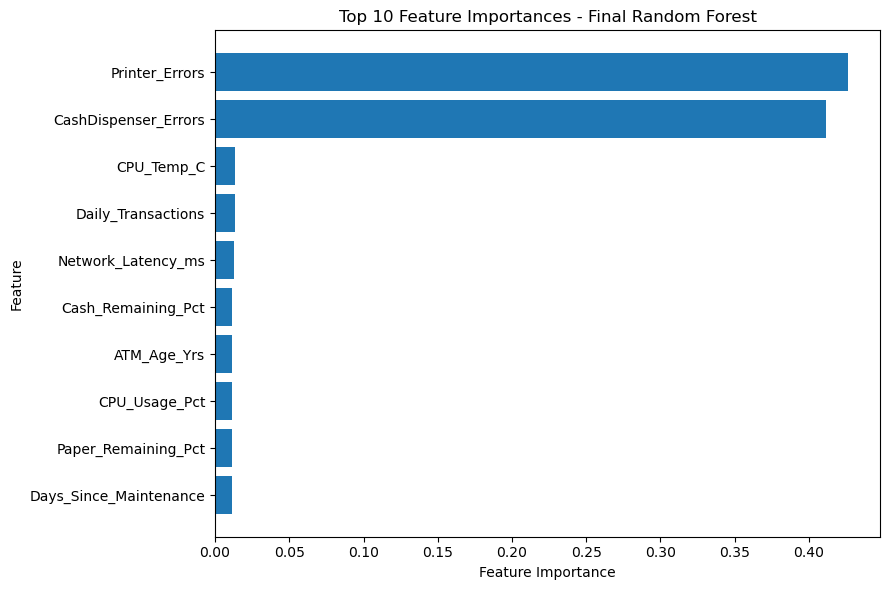

In [53]:
import matplotlib.pyplot as plt

top_10 = final_importance.head(10).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_10['Feature'],
    top_10['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 10 Feature Importances - Final Random Forest')

plt.tight_layout()
plt.show()

### Feature Importance Interpretation

The final Random Forest model shows that `Printer_Errors` and `CashDispenser_Errors` are the most influential predictors, with importance scores of approximately 0.427 and 0.411 respectively.

Together, these two variables account for most of the model's predictive importance. Other variables such as CPU temperature, daily transactions, network latency, cash remaining percentage, ATM age, and CPU usage make much smaller contributions.

This is consistent with the earlier investigation of the original synthetic target, where printer errors and cash dispenser errors were found to be major components of the deterministic failure rule.

After introducing simulated noise, these features remain dominant, although the model no longer achieves perfect prediction.

## Simulated Failure Risk Prediction for Each ATM

The final Random Forest model is used to generate a simulated failure-risk prediction for each ATM based on its most recent available record.

For each ATM, the latest observation is selected and passed to the trained model. The model produces both a predicted class and a probability score.

- `0` represents **No Failure**
- `1` represents **Failure**

The failure probability is used to rank ATMs so that higher-risk machines can be prioritized for inspection or preventive maintenance.

These predictions are based on a model trained using a simulated noisy target and therefore represent a demonstration of a predictive-maintenance workflow rather than validated real-world failure probabilities.

In [54]:
latest_atm = (
    atm.sort_values('Date')
       .groupby('ATM_ID')
       .tail(1)
       .copy()
)

print("Number of ATMs:", len(latest_atm))

Number of ATMs: 300


In [55]:
X_latest = latest_atm[X_train.columns].copy()

print("Prediction feature shape:", X_latest.shape)

Prediction feature shape: (300, 23)


In [56]:
X_latest

,District,Location_Type,Manufacturer,ATM_Age_Yrs,Daily_Transactions,Failed_Transactions,Cash_Remaining_Pct,Cash_Loaded_Today,CardReader_Errors,CashDispenser_Errors,...,CPU_Temp_C,CPU_Usage_Pct,Memory_Usage_Pct,Network_Latency_ms,Network_Drops,UPS_Battery_Pct,Power_Outages_7D,Days_Since_Maintenance,Previous_Failures_90D,Customer_Complaints_7D
47948,6,1,2,9.9,639,13,81.0,0,1,0,...,52.5,53,54,87,0,100,1,44,0,4
48190,2,0,0,2.7,459,0,25.0,0,0,3,...,45.5,58,65,77,0,76,0,37,1,0
48589,8,0,1,3.2,352,11,72.0,0,2,1,...,48.2,55,52,45,3,100,0,51,4,0
48566,7,1,1,3.2,220,7,57.0,0,1,3,...,42.7,21,62,127,0,91,0,0,0,1
48549,7,0,0,1.2,413,16,14.0,0,0,3,...,43.5,41,60,59,3,100,2,50,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49909,6,1,2,8.9,423,7,67.0,0,2,0,...,40.3,12,48,69,0,81,0,63,1,0
49910,2,1,1,9.4,429,12,58.0,1,0,1,...,49.1,53,53,52,1,90,0,40,1,0
49911,2,2,1,9.8,687,30,57.0,1,0,1,...,51.4,47,58,10,0,83,1,40,5,0
49905,5,4,0,2.9,453,19,62.0,0,1,0,...,50.4,78,69,77,0,86,0,47,0,1


In [57]:
# Predict class
latest_predictions = final_model.predict(X_latest)

# Predict probability of Failure
latest_probabilities = final_model.predict_proba(X_latest)[:, 1]

In [58]:
latest_atm['Predicted_Failure'] = latest_predictions

latest_atm['Failure_Probability'] = (
    latest_probabilities * 100
).round(2)

In [59]:
latest_atm

,Date,ATM_ID,District,Location_Type,Manufacturer,ATM_Age_Yrs,Daily_Transactions,Failed_Transactions,Cash_Remaining_Pct,Cash_Loaded_Today,...,UPS_Battery_Pct,Power_Outages_7D,Days_Since_Maintenance,Previous_Failures_90D,Customer_Complaints_7D,Failure_Code,Failure_Next_48H,Failure_Noisy,Predicted_Failure,Failure_Probability
47948,2025-12-16,ATM162,6,1,2,9.9,639,13,81.0,0,...,100,1,44,0,4,5,1,1,1,89.10
48190,2025-12-18,ATM277,2,0,0,2.7,459,0,25.0,0,...,76,0,37,1,0,3,1,1,1,92.28
48589,2025-12-21,ATM216,8,0,1,3.2,352,11,72.0,0,...,100,0,51,4,0,0,0,0,0,9.90
48566,2025-12-21,ATM267,7,1,1,3.2,220,7,57.0,0,...,91,0,0,0,1,6,1,0,1,90.59
48549,2025-12-21,ATM252,7,0,0,1.2,413,16,14.0,0,...,100,2,50,1,1,1,1,1,1,84.74
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49909,2025-12-31,ATM231,6,1,2,8.9,423,7,67.0,0,...,81,0,63,1,0,0,0,0,0,8.40
49910,2025-12-31,ATM097,2,1,1,9.4,429,12,58.0,1,...,90,0,40,1,0,0,0,0,0,3.91
49911,2025-12-31,ATM041,2,2,1,9.8,687,30,57.0,1,...,83,1,40,5,0,0,0,1,0,16.79
49905,2025-12-31,ATM210,5,4,0,2.9,453,19,62.0,0,...,86,0,47,0,1,0,0,0,0,6.91


In [60]:
predicted_failure = latest_atm[
    latest_atm['Predicted_Failure'] == 1
].copy()

predicted_ok = latest_atm[
    latest_atm['Predicted_Failure'] == 0
].copy()

In [61]:
predicted_failure = predicted_failure.sort_values(
    by='Failure_Probability',
    ascending=False
)

predicted_ok = predicted_ok.sort_values(
    by='Failure_Probability',
    ascending=False
)

In [62]:
predicted_failure

,Date,ATM_ID,District,Location_Type,Manufacturer,ATM_Age_Yrs,Daily_Transactions,Failed_Transactions,Cash_Remaining_Pct,Cash_Loaded_Today,...,UPS_Battery_Pct,Power_Outages_7D,Days_Since_Maintenance,Previous_Failures_90D,Customer_Complaints_7D,Failure_Code,Failure_Next_48H,Failure_Noisy,Predicted_Failure,Failure_Probability
49919,2025-12-31,ATM063,6,3,2,8.8,514,16,69.0,0,...,87,3,13,0,0,6,1,1,1,95.43
49908,2025-12-31,ATM180,6,1,1,7.2,337,15,65.0,0,...,87,3,71,0,0,3,1,1,1,95.36
49748,2025-12-30,ATM071,9,2,1,5.0,325,4,54.0,1,...,89,3,26,3,0,3,1,1,1,95.01
49886,2025-12-31,ATM072,8,3,1,3.4,511,13,75.0,0,...,81,0,19,5,0,6,1,1,1,94.62
49619,2025-12-29,ATM019,9,3,0,6.6,571,12,35.0,0,...,93,1,56,0,0,3,1,1,1,94.42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49755,2025-12-30,ATM200,4,1,2,10.0,358,0,84.0,0,...,85,0,58,0,3,1,1,1,1,83.70
49595,2025-12-29,ATM061,5,2,1,7.0,430,4,9.0,0,...,81,1,8,1,0,5,1,1,1,83.62
49989,2025-12-31,ATM029,2,0,1,3.0,749,22,17.0,0,...,78,0,0,0,0,2,1,1,1,83.22
49700,2025-12-29,ATM248,8,3,2,1.1,307,7,80.0,0,...,70,0,100,6,3,3,1,1,1,80.47


In [63]:
predicted_ok

,Date,ATM_ID,District,Location_Type,Manufacturer,ATM_Age_Yrs,Daily_Transactions,Failed_Transactions,Cash_Remaining_Pct,Cash_Loaded_Today,...,UPS_Battery_Pct,Power_Outages_7D,Days_Since_Maintenance,Previous_Failures_90D,Customer_Complaints_7D,Failure_Code,Failure_Next_48H,Failure_Noisy,Predicted_Failure,Failure_Probability
49888,2025-12-31,ATM140,3,3,0,5.3,265,10,77.0,1,...,93,0,32,2,1,0,0,1,0,36.77
49981,2025-12-31,ATM205,6,0,1,5.8,98,3,41.0,0,...,93,6,25,2,1,0,0,0,0,17.53
49911,2025-12-31,ATM041,2,2,1,9.8,687,30,57.0,1,...,83,1,40,5,0,0,0,1,0,16.79
49392,2025-12-27,ATM185,6,2,0,4.7,259,4,37.0,0,...,83,2,28,2,1,0,0,0,0,15.57
49847,2025-12-30,ATM074,4,5,2,3.9,669,13,45.0,1,...,87,2,62,0,5,0,0,0,0,14.20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49580,2025-12-28,ATM035,1,2,0,2.4,462,9,28.0,1,...,95,0,6,1,3,0,0,0,0,4.07
49628,2025-12-29,ATM112,4,5,1,8.0,442,20,52.0,0,...,78,0,15,0,0,0,0,0,0,3.95
49910,2025-12-31,ATM097,2,1,1,9.4,429,12,58.0,1,...,90,0,40,1,0,0,0,0,0,3.91
49359,2025-12-27,ATM204,8,1,0,6.2,373,4,44.0,1,...,78,0,51,0,0,0,0,0,0,3.81


In [64]:
print("Total ATMs:", len(latest_atm))

print(
    "Predicted Failure:",
    len(predicted_failure)
)

print(
    "Predicted No Failure:",
    len(predicted_ok)
)

Total ATMs: 300
Predicted Failure: 139
Predicted No Failure: 161


In [65]:
predicted_failure[
    [
        'ATM_ID',
        'Date',
        'Predicted_Failure',
        'Failure_Probability'
    ]
].head(10)

,ATM_ID,Date,Predicted_Failure,Failure_Probability
49919,ATM063,2025-12-31,1,95.43
49908,ATM180,2025-12-31,1,95.36
49748,ATM071,2025-12-30,1,95.01
49886,ATM072,2025-12-31,1,94.62
49619,ATM019,2025-12-29,1,94.42
49253,ATM223,2025-12-26,1,94.35
49946,ATM177,2025-12-31,1,94.17
49869,ATM104,2025-12-31,1,93.76
49618,ATM109,2025-12-29,1,93.49
49818,ATM053,2025-12-30,1,93.46


In [66]:
prediction_output = latest_atm[
    [
        'ATM_ID',
        'Date',
        'Predicted_Failure',
        'Failure_Probability'
    ]
].copy()

prediction_output.head()

,ATM_ID,Date,Predicted_Failure,Failure_Probability
47948,ATM162,2025-12-16,1,89.10
48190,ATM277,2025-12-18,1,92.28
48589,ATM216,2025-12-21,0,9.90
48566,ATM267,2025-12-21,1,90.59
48549,ATM252,2025-12-21,1,84.74


In [67]:
## Save all ATM predictions
prediction_output.to_csv(
    'Dataset/ATM_Latest_Predictions.csv',
    index=False
)

In [68]:
## Save the predicted-failure ATMs
failure_output = predicted_failure[
    [
        'ATM_ID',
        'Date',
        'Predicted_Failure',
        'Failure_Probability'
    ]
]

failure_output.to_csv(
    'Dataset/ATM_Predicted_Failures.csv',
    index=False
)

In [69]:
## Save the predicted-OK ATM
ok_output = predicted_ok[
    [
        'ATM_ID',
        'Date',
        'Predicted_Failure',
        'Failure_Probability'
    ]
]

ok_output.to_csv(
    'Dataset/ATM_Predicted_OK.csv',
    index=False
)

In [70]:
import joblib

# Save final Random Forest
joblib.dump(
    final_model,
    'Models/model.joblib'
)

# Save feature columns
joblib.dump(
    list(X_train.columns),
    'Models/feature_cols.joblib'
)

print("Model and feature columns saved successfully.")

Model and feature columns saved successfully.


In [71]:
joblib.dump(
    encoders,
    'Models/encoders.joblib'
)

['Models/encoders.joblib']